# Studi Kasus 3 — *Career and Competition in Industrial Era with GIS*

**Pemateri:** Widi Prima Deva, S.Kom. — Asset Management GIS Analyst, Citycare Property (Christchurch, Selandia Baru);
alumni Informatika Universitas Bengkulu
**Video:** https://www.youtube.com/live/TkXkx7HKTto
**Seri:** Informatics Practitioner Lecture Series 2026 — Prodi Informatika Universitas Bengkulu

---

## Ringkasan materi pemateri

1. **Lulusan IT "one step ahead" di GIS**: bukan hanya *end user* perangkat lunak GIS, tetapi bisa menjadi
   **developer** (Python, SQL/PostGIS, JavaScript, API, cloud, aplikasi *mobile* untuk survei lapangan).
2. **GIS dibutuhkan hampir semua industri** — contoh: Indomaret memakai data spasial untuk memilih lokasi gerai
   (radius antar-gerai, populasi sekitar) dan efisiensi logistik; perusahaan logistik, pertambangan (AMDAL), energi
   (PLTM), pertanian pangan berkelanjutan, hingga radio komunikasi darurat.
3. Pekerjaan beliau di **asset management**: *data capture* di lapangan → *post-processing* → data diserahkan ke
   City Council. Ekosistem industri: ArcGIS Enterprise, **FME**, Field Maps; di sisi *open source*: **QGIS, PostGIS,
   GeoPandas**.
4. Kendala di Indonesia: data antarinstansi tidak sinkron, perangkat mahal (GPS RTK seharga mobil), masih banyak
   software bajakan & alur kerja *offline* (pindah data GPS manual ke laptop).
5. **Visi pemateri**: membangun ekosistem GIS sendiri berbasis *open source* (pengganti GIS enterprise) yang
   terintegrasi dari aplikasi lapangan sampai portal web, agar kampus tidak bergantung pada software berbayar/bajakan.
6. Tips karier: pilih jalur akademik atau industri dengan serius, bangun pengalaman & portofolio (GitHub, LinkedIn),
   jangan ada "kekosongan" dalam riwayat kerja.

## Latar belakang studi kasus

Sebuah jaringan minimarket ingin membuka **gerai baru di Kota Bengkulu**. Seperti contoh Indomaret dari pemateri,
keputusan lokasi harus mempertimbangkan populasi sekitar, jarak ke gerai yang sudah ada (agar tidak saling
"mengkanibal"), akses jalan, dan risiko bencana (banjir/abrasi pantai). Setelah gerai dipilih, tim operasional
juga butuh **rute logistik** dari gudang dan **manajemen aset** (inventaris & prioritas pemeliharaan aset gerai/PJU).

Semua dikerjakan dengan **tumpukan open source (GeoPandas, Shapely, Folium)** sesuai visi pemateri, dan hasilnya
diekspor ke format terbuka (GeoPackage/GeoJSON) yang bisa dibuka di QGIS atau dimuat ke PostGIS.

> ⚠️ **Data sintetis.** Batas wilayah, jalan, sungai, populasi, dan titik gerai **disederhanakan/dibangkitkan**
> untuk keperluan belajar, bukan data resmi. Untuk proyek nyata gunakan data BIG/BPS/OpenStreetMap.

## Tujuan
1. Membangun & memproyeksikan data spasial (CRS geografis → UTM 48S).
2. Analisis spasial: *buffer*, *overlay* (intersection), *spatial join*, *nearest*, analisis multikriteria.
3. Optimasi rute logistik sederhana.
4. Alur manajemen aset: validasi data survei lapangan (akurasi GNSS), pembaruan inventaris, prioritas pemeliharaan.
5. Peta web interaktif & ekspor ke format terbuka.

## 0. Persiapan

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from shapely.geometry import Point, Polygon, LineString, box
from shapely.ops import unary_union

rng = np.random.default_rng(17)
CRS_GEO, CRS_UTM = "EPSG:4326", "EPSG:32748"   # WGS84 & UTM zona 48S (meter) — sesuai lokasi Bengkulu
print("GeoPandas", gpd.__version__)

GeoPandas 1.2.0


## 1. Membangun data spasial wilayah studi

### 1.1 Batas wilayah, sungai, garis pantai, dan jalan utama (disederhanakan)

In [2]:
wilayah = gpd.GeoDataFrame({"nama": ["Wilayah studi (Kota Bengkulu, disederhanakan)"]}, geometry=[Polygon([
    (102.245, -3.735), (102.252, -3.786), (102.262, -3.805), (102.285, -3.840), (102.300, -3.872),
    (102.312, -3.900), (102.362, -3.900), (102.385, -3.835), (102.372, -3.770), (102.340, -3.735)])], crs=CRS_GEO)

sungai = gpd.GeoDataFrame({"nama": ["Sungai (sintetis)"]}, geometry=[LineString([
    (102.372, -3.752), (102.330, -3.758), (102.300, -3.765), (102.270, -3.770), (102.249, -3.772)])], crs=CRS_GEO)

pantai = gpd.GeoDataFrame({"nama": ["Garis pantai"]}, geometry=[LineString(list(wilayah.geometry[0].exterior.coords)[:7])],
                          crs=CRS_GEO)

jalan = gpd.GeoDataFrame({
    "nama": ["Jalan A (pusat–timur)", "Jalan B (utara–selatan)", "Jalan C (lingkar barat)", "Jalan D (pantai)",
             "Jalan E (kampus)"],
    "kelas": ["arteri", "arteri", "kolektor", "kolektor", "lokal"]},
    geometry=[LineString([(102.262, -3.797), (102.300, -3.800), (102.340, -3.805), (102.375, -3.810)]),
              LineString([(102.280, -3.745), (102.285, -3.790), (102.292, -3.840), (102.310, -3.890)]),
              LineString([(102.268, -3.815), (102.300, -3.830), (102.335, -3.845), (102.360, -3.860)]),
              LineString([(102.258, -3.792), (102.270, -3.812), (102.290, -3.845), (102.305, -3.880)]),
              LineString([(102.265, -3.760), (102.280, -3.758), (102.300, -3.760)])], crs=CRS_GEO)

# semua analisis jarak dilakukan dalam meter (UTM)
wil_u, sungai_u, pantai_u, jalan_u = [g.to_crs(CRS_UTM) for g in (wilayah, sungai, pantai, jalan)]
print(f"Luas wilayah studi: {wil_u.area.iloc[0] / 1e6:,.1f} km²")

Luas wilayah studi: 200.3 km²


### 1.2 Grid populasi 500 m (pengganti data BPS per kelurahan)
Kepadatan dimodelkan sebagai beberapa pusat keramaian (pasar/pusat kota, kawasan kampus, permukiman timur).

846 sel grid, total penduduk sintetis ≈ 389,988


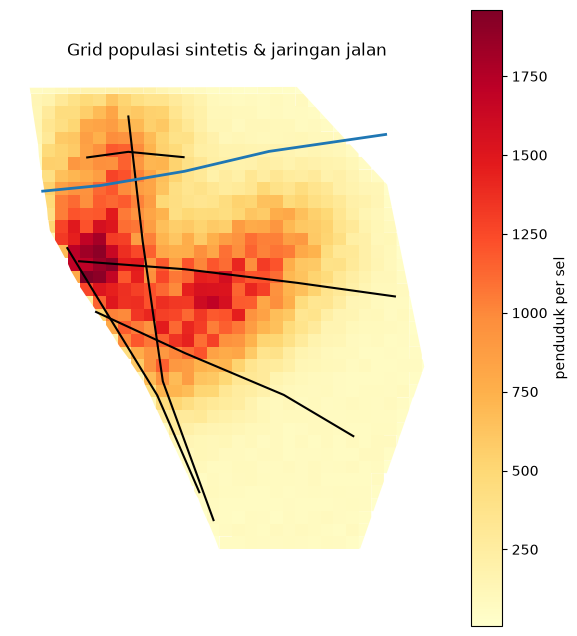

In [3]:
xmin, ymin, xmax, ymax = wil_u.total_bounds
UK = 500
sel = [box(x, y, x + UK, y + UK) for x in np.arange(xmin, xmax, UK) for y in np.arange(ymin, ymax, UK)]
grid = gpd.GeoDataFrame(geometry=sel, crs=CRS_UTM)
grid = gpd.overlay(grid, wil_u[["geometry"]], how="intersection")      # potong mengikuti batas wilayah
grid = grid[grid.area > 20_000].reset_index(drop=True)

pusat = gpd.GeoSeries(gpd.points_from_xy([102.265, 102.276, 102.312, 102.290, 102.335],
                                         [-3.797, -3.758, -3.810, -3.830, -3.790]), crs=CRS_GEO).to_crs(CRS_UTM)
bobot_pusat = [9000, 5000, 6000, 4000, 3500]
c = grid.centroid
kepadatan = sum(w * np.exp(-(c.distance(p) / 2500) ** 2) for p, w in zip(pusat, bobot_pusat)) + 400
mentah = kepadatan * grid.area / 250_000 * rng.uniform(0.8, 1.2, len(grid))
grid["penduduk"] = (mentah / mentah.sum() * 390_000).round()          # total ≈ penduduk Kota Bengkulu (±390 ribu)
print(f"{len(grid)} sel grid, total penduduk sintetis ≈ {grid.penduduk.sum():,.0f}")

ax = grid.plot("penduduk", cmap="YlOrRd", legend=True, figsize=(7, 8), legend_kwds={"label": "penduduk per sel"})
jalan_u.plot(ax=ax, color="black", lw=1.5); sungai_u.plot(ax=ax, color="tab:blue", lw=2)
ax.set_title("Grid populasi sintetis & jaringan jalan"); ax.set_axis_off(); plt.show()

### 1.3 Gerai eksisting, gerai pesaing, dan calon lokasi

In [4]:
# Gerai ritel umumnya berada di tepi jalan (ruko). Kita bangkitkan "kavling" setiap 40 m di kiri-kanan jalan,
# dengan jarak acak 0–400 m dari as jalan, lalu memilihnya berdasarkan kepadatan penduduk di lokasi tersebut.
kavling = []
for g in jalan_u.geometry:
    for d in np.arange(0, g.length, 40):
        p0, p1 = g.interpolate(d), g.interpolate(min(d + 1, g.length))
        nx, ny = -(p1.y - p0.y), (p1.x - p0.x); L = np.hypot(nx, ny) or 1
        off = rng.choice([-1, 1]) * rng.exponential(120)
        kavling.append(Point(p0.x + nx / L * off, p0.y + ny / L * off))
kavling = gpd.GeoDataFrame(geometry=kavling, crs=CRS_UTM)
kavling = gpd.sjoin(kavling, grid[["penduduk", "geometry"]], predicate="within").drop(columns="index_right")
kavling = kavling[kavling.distance(jalan_u.union_all()) <= 400].reset_index(drop=True)

def pilih_kavling(n, pangkat):
    w = kavling.penduduk.values ** pangkat
    return kavling.geometry.iloc[rng.choice(len(kavling), n, replace=False, p=w / w.sum())].reset_index(drop=True)

gerai = gpd.GeoDataFrame({"id_gerai": [f"G{i:02d}" for i in range(1, 31)]}, geometry=pilih_kavling(30, 1.5))
pesaing = gpd.GeoDataFrame({"id_pesaing": [f"K{i:02d}" for i in range(1, 26)]}, geometry=pilih_kavling(25, 1.3))
kandidat = gpd.GeoDataFrame({"id_kandidat": [f"L{i:02d}" for i in range(1, 41)]}, geometry=pilih_kavling(40, 0.5))
gudang = gpd.GeoDataFrame({"nama": ["Gudang distribusi"]},
                          geometry=gpd.points_from_xy([102.340], [-3.850]), crs=CRS_GEO).to_crs(CRS_UTM)
len(gerai), len(pesaing), len(kandidat)

(30, 25, 40)

## 2. Analisis kesesuaian lokasi (multikriteria)

| Kriteria | Cara hitung (operasi spasial) | Jenis |
|---|---|---|
| Penduduk dalam radius 500 m | *buffer* 500 m → *overlay intersection* dengan grid → bobot luas | maksimalkan |
| Jarak ke gerai sendiri terdekat | `sjoin_nearest` | **wajib ≥ 300 m** (anti-kanibalisasi), lalu maksimalkan s.d. 1 km |
| Jumlah pesaing dalam 500 m | *buffer* + `sjoin` + hitung | minimalkan |
| Jarak ke jalan arteri/kolektor | `distance` ke garis | **wajib ≤ 250 m**, lalu minimalkan |
| Zona risiko | *buffer* sungai 300 m ∪ *buffer* pantai 250 m | **wajib di luar zona** |

In [5]:
kand = kandidat.copy()

# (1) penduduk dalam 500 m — area-weighted
buf = kand.copy(); buf["geometry"] = kand.buffer(500)
grid["luas_sel"] = grid.area
irisan = gpd.overlay(buf, grid[["penduduk", "luas_sel", "geometry"]], how="intersection")
irisan["pend_terbobot"] = irisan.penduduk * irisan.area / irisan.luas_sel
kand["penduduk_500m"] = kand.id_kandidat.map(irisan.groupby("id_kandidat").pend_terbobot.sum()).fillna(0).round()

# (2) jarak ke gerai sendiri terdekat
kand = gpd.sjoin_nearest(kand, gerai, how="left", distance_col="jarak_gerai_m").drop(columns="index_right")
kand = kand.drop_duplicates("id_kandidat")

# (3) jumlah pesaing dalam 500 m
hit = gpd.sjoin(pesaing, buf[["id_kandidat", "geometry"]], predicate="within").groupby("id_kandidat").size()
kand["pesaing_500m"] = kand.id_kandidat.map(hit).fillna(0).astype(int)

# (4) jarak ke jalan utama
jalan_utama = jalan_u[jalan_u.kelas.isin(["arteri", "kolektor"])].union_all()
kand["jarak_jalan_m"] = kand.distance(jalan_utama).round()

# (5) zona risiko
zona_risiko = unary_union([sungai_u.buffer(300).union_all(), pantai_u.buffer(250).union_all()])
kand["zona_risiko"] = kand.intersects(zona_risiko)

def norm(s, naik=True):
    s = (s - s.min()) / (s.max() - s.min() + 1e-9)
    return s if naik else 1 - s

kand["lolos_syarat"] = (kand.jarak_gerai_m >= 300) & (kand.jarak_jalan_m <= 250) & (~kand.zona_risiko)
BOBOT = {"penduduk": 0.45, "jarak_gerai": 0.20, "pesaing": 0.20, "akses_jalan": 0.15}
kand["skor"] = (BOBOT["penduduk"] * norm(kand.penduduk_500m)
                + BOBOT["jarak_gerai"] * norm(kand.jarak_gerai_m.clip(upper=1000))
                + BOBOT["pesaing"] * norm(kand.pesaing_500m, naik=False)
                + BOBOT["akses_jalan"] * norm(kand.jarak_jalan_m, naik=False))
kand.loc[~kand.lolos_syarat, "skor"] = 0
peringkat = kand.sort_values("skor", ascending=False)
kolom = ["id_kandidat", "penduduk_500m", "jarak_gerai_m", "pesaing_500m", "jarak_jalan_m", "zona_risiko", "lolos_syarat", "skor"]
peringkat[kolom].head(10).round(2)

,id_kandidat,penduduk_500m,jarak_gerai_m,pesaing_500m,jarak_jalan_m,zona_risiko,lolos_syarat,skor
14,L15,5448.0,327.12,0,174.0,False,True,0.84
32,L33,4040.0,904.25,1,229.0,False,True,0.78
2,L03,3437.0,2100.54,1,9.0,False,True,0.77
0,L01,4298.0,600.92,1,54.0,False,True,0.76
33,L34,3286.0,1234.81,1,182.0,False,True,0.74
19,L20,3013.0,1089.67,1,36.0,False,True,0.74
37,L38,3983.0,303.24,0,4.0,False,True,0.73
9,L10,3416.0,1029.38,3,7.0,False,True,0.67
39,L40,1683.0,1274.02,0,119.0,False,True,0.66
3,L04,3114.0,407.89,0,159.0,False,True,0.66


In [6]:
print("Kandidat gugur karena syarat wajib:")
print("  terlalu dekat gerai sendiri (<300 m):", int((kand.jarak_gerai_m < 300).sum()))
print("  jauh dari jalan utama (>250 m)      :", int((kand.jarak_jalan_m > 250).sum()))
print("  berada di zona risiko               :", int(kand.zona_risiko.sum()))
TERPILIH = peringkat[peringkat.lolos_syarat].head(5)
print("\nRekomendasi 5 lokasi:", ", ".join(TERPILIH.id_kandidat))

Kandidat gugur karena syarat wajib:
  terlalu dekat gerai sendiri (<300 m): 11
  jauh dari jalan utama (>250 m)      : 5
  berada di zona risiko               : 7

Rekomendasi 5 lokasi: L15, L33, L03, L01, L34


**Uji sensitivitas bobot.** Keputusan lokasi tidak boleh bergantung pada satu set bobot yang "kebetulan". Kita ubah
bobot secara acak ±50% sebanyak 500 kali dan menghitung seberapa sering tiap kandidat masuk 5 besar.

In [7]:
lolos = kand[kand.lolos_syarat].copy()
komponen = pd.DataFrame({
    "penduduk": norm(lolos.penduduk_500m), "jarak_gerai": norm(lolos.jarak_gerai_m.clip(upper=1000)),
    "pesaing": norm(lolos.pesaing_500m, naik=False), "akses_jalan": norm(lolos.jarak_jalan_m, naik=False)})
w0 = np.array(list(BOBOT.values()))
frek = pd.Series(0, index=lolos.id_kandidat.values)
for _ in range(500):
    w = w0 * rng.uniform(0.5, 1.5, 4); w /= w.sum()
    top5 = lolos.id_kandidat.values[np.argsort(-(komponen.values @ w))[:5]]
    frek[top5] += 1
(frek.sort_values(ascending=False).head(8) / 5).rename("% masuk top-5").to_frame()

,% masuk top-5
L03,100.0
L20,94.0
L01,90.4
L15,64.0
L38,53.0
L10,44.8
L33,23.6
L34,17.4


## 3. Rute logistik dari gudang
Truk berangkat dari gudang, mengunjungi 5 gerai baru + 10 gerai eksisting terdekat dengan gudang, lalu kembali.
Kita pakai heuristik *nearest neighbour* lalu diperbaiki dengan **2-opt** (algoritma klasik TSP).

In [8]:
dekat_gudang = gerai.assign(j=gerai.distance(gudang.geometry.iloc[0])).nsmallest(10, "j")
titik = pd.concat([gudang.geometry, TERPILIH.geometry, dekat_gudang.geometry], ignore_index=True)
label = ["GUDANG"] + list(TERPILIH.id_kandidat) + list(dekat_gudang.id_gerai)
XY = np.c_[titik.x, titik.y]
D = np.linalg.norm(XY[:, None, :] - XY[None, :, :], axis=2) * 1.3     # faktor 1,3: jalan tidak lurus

def panjang(rute): return sum(D[rute[i], rute[i + 1]] for i in range(len(rute) - 1))

def nearest_neighbour():
    rute, sisa = [0], set(range(1, len(XY)))
    while sisa:
        nxt = min(sisa, key=lambda j: D[rute[-1], j]); rute.append(nxt); sisa.remove(nxt)
    return rute + [0]

def two_opt(rute):
    baik = True
    while baik:
        baik = False
        for i in range(1, len(rute) - 2):
            for k in range(i + 1, len(rute) - 1):
                baru = rute[:i] + rute[i:k + 1][::-1] + rute[k + 1:]
                if panjang(baru) < panjang(rute) - 1e-6:
                    rute, baik = baru, True
    return rute

r_nn = nearest_neighbour(); r_2opt = two_opt(r_nn)
print(f"Nearest neighbour: {panjang(r_nn) / 1000:.1f} km | setelah 2-opt: {panjang(r_2opt) / 1000:.1f} km")
print("Urutan kunjungan:", " → ".join(label[i] for i in r_2opt))

Nearest neighbour: 40.9 km | setelah 2-opt: 33.8 km
Urutan kunjungan: GUDANG → G22 → G18 → G26 → L33 → L01 → G24 → G12 → G11 → G14 → G06 → L15 → G15 → L34 → L03 → G30 → GUDANG


## 4. Manajemen aset: dari survei lapangan ke inventaris

Alur kerja pemateri: **data capture → post-processing → submit**. Contoh aset: **lampu penerangan jalan (PJU)**
di sepanjang jalan utama yang mendukung keamanan akses gerai.

### 4.1 Inventaris aset (basis data induk)

In [9]:
titik_pju, kelas_pju = [], []
for _, r in jalan_u.iterrows():
    for d in np.arange(0, r.geometry.length, 120):
        titik_pju.append(r.geometry.interpolate(d)); kelas_pju.append(r.kelas)
aset = gpd.GeoDataFrame({
    "id_aset": [f"PJU-{i:04d}" for i in range(len(titik_pju))],
    "kelas_jalan": kelas_pju,
    "tahun_pasang": rng.integers(2008, 2025, len(titik_pju)),
    "kondisi": rng.choice([1, 2, 3, 4, 5], len(titik_pju), p=[0.08, 0.15, 0.3, 0.3, 0.17]),  # 1=rusak, 5=baik
}, geometry=titik_pju, crs=CRS_UTM)
print("Jumlah aset PJU:", len(aset))
aset.head()

Jumlah aset PJU: 465


,id_aset,kelas_jalan,tahun_pasang,kondisi,geometry
0,PJU-0000,arteri,2016,2,POINT (195877.931 9579829.769)
1,PJU-0001,arteri,2024,5,POINT (195997.592 9579820.743)
2,PJU-0002,arteri,2014,2,POINT (196117.252 9579811.717)
3,PJU-0003,arteri,2010,4,POINT (196236.912 9579802.691)
4,PJU-0004,arteri,2013,3,POINT (196356.572 9579793.666)


### 4.2 Validasi data survei lapangan (GPS ponsel)
Petugas mengisi formulir di ponsel (koordinat + kondisi terbaru). Pemateri menekankan: GPS ponsel memakai satelit yang
sama (GPS/GLONASS/Galileo/BeiDou), tetapi **akurasinya harus dicek** sebelum data masuk ke basis data induk.

In [10]:
sampel = aset.sample(60, random_state=3)
geo_sampel = sampel.to_crs(CRS_GEO)
survei = pd.DataFrame({
    "id_aset": sampel.id_aset.values,
    "lat": geo_sampel.geometry.y.values + rng.normal(0, 0.00003, 60),
    "lon": geo_sampel.geometry.x.values + rng.normal(0, 0.00003, 60),
    "akurasi_m": np.round(rng.gamma(2, 2.2, 60), 1),
    "kondisi_baru": np.clip(sampel.kondisi.values - rng.choice([0, 0, 1, 2], 60), 1, 5),
    "tanggal": pd.Timestamp("2026-10-01") + pd.to_timedelta(rng.integers(0, 14, 60), unit="D"),
})
survei.loc[[5, 17], "lat"] = survei.loc[[5, 17], "lat"] + 0.01           # 2 titik salah tagging (~1 km)
survei_g = gpd.GeoDataFrame(survei, geometry=gpd.points_from_xy(survei.lon, survei.lat), crs=CRS_GEO).to_crs(CRS_UTM)

# aturan QC: akurasi GNSS ≤ 10 m DAN posisi ≤ 25 m dari aset di basis data
pos_induk = aset.set_index("id_aset").geometry.loc[survei_g.id_aset].values
survei_g["selisih_posisi_m"] = survei_g.distance(gpd.GeoSeries(pos_induk, crs=CRS_UTM), align=False).round(1)
survei_g["lolos_qc"] = (survei_g.akurasi_m <= 10) & (survei_g.selisih_posisi_m <= 25)
print(survei_g.lolos_qc.value_counts().rename({True: "lolos", False: "ditolak / perlu survei ulang"}))
survei_g.loc[~survei_g.lolos_qc, ["id_aset", "akurasi_m", "selisih_posisi_m"]]

lolos_qc
lolos                           51
ditolak / perlu survei ulang     9
Name: count, dtype: int64


,id_aset,akurasi_m,selisih_posisi_m
5,PJU-0107,9.7,1102.2
11,PJU-0159,11.4,8.5
17,PJU-0088,4.0,1111.3
28,PJU-0282,10.8,4.1
32,PJU-0255,10.7,3.0
39,PJU-0397,11.5,0.8
41,PJU-0114,16.5,3.6
44,PJU-0051,10.4,5.2
48,PJU-0083,11.6,2.6


In [11]:
# post-processing: perbarui kondisi aset hanya dari data yang lolos QC
upd = survei_g[survei_g.lolos_qc].set_index("id_aset")
aset = aset.set_index("id_aset")
aset.loc[upd.index, "kondisi"] = upd.kondisi_baru
aset.loc[upd.index, "tgl_inspeksi"] = upd.tanggal
aset = aset.reset_index()
print("Aset diperbarui:", len(upd))

Aset diperbarui: 51


### 4.3 Prioritas pemeliharaan dengan anggaran terbatas
Skor risiko = (6 − kondisi) × kekritisan. Kekritisan lebih tinggi untuk jalan arteri dan PJU di dekat gerai
(lalu lintas pejalan kaki). Anggaran: Rp150 juta; biaya perbaikan bergantung kondisi.

In [12]:
dekat_gerai = aset.geometry.apply(lambda g: gerai.distance(g).min() <= 200)
aset["kekritisan"] = aset.kelas_jalan.map({"arteri": 3, "kolektor": 2, "lokal": 1}) + dekat_gerai.astype(int)
aset["umur"] = 2026 - aset.tahun_pasang
aset["skor_risiko"] = (6 - aset.kondisi) * aset.kekritisan + 0.1 * aset.umur
aset["biaya_perbaikan"] = aset.kondisi.map({1: 9e6, 2: 6e6, 3: 3.5e6, 4: 1.5e6, 5: 0})

ANGGARAN = 150e6
urut = aset[aset.kondisi <= 3].sort_values("skor_risiko", ascending=False)
urut["kumulatif"] = urut.biaya_perbaikan.cumsum()
rencana = urut[urut.kumulatif <= ANGGARAN]
aset["rencana_2027"] = aset.id_aset.isin(rencana.id_aset)
biaya = f"{rencana.biaya_perbaikan.sum():,.0f}".replace(",", ".")
print(f"Aset diperbaiki tahun depan: {len(rencana)} unit; biaya Rp{biaya}")
rencana[["id_aset", "kelas_jalan", "kondisi", "kekritisan", "umur", "skor_risiko", "biaya_perbaikan"]].head(10)

Aset diperbaiki tahun depan: 18 unit; biaya Rp147.000.000


,id_aset,kelas_jalan,kondisi,kekritisan,umur,skor_risiko,biaya_perbaikan
37,PJU-0037,arteri,1,4,13,21.3,9000000.0
136,PJU-0136,arteri,1,4,12,21.2,9000000.0
47,PJU-0047,arteri,1,4,9,20.9,9000000.0
15,PJU-0015,arteri,1,4,5,20.5,9000000.0
159,PJU-0159,arteri,1,4,2,20.2,9000000.0
26,PJU-0026,arteri,2,4,17,17.7,6000000.0
9,PJU-0009,arteri,2,4,14,17.4,6000000.0
171,PJU-0171,arteri,2,4,11,17.1,6000000.0
46,PJU-0046,arteri,2,4,8,16.8,6000000.0
68,PJU-0068,arteri,1,3,18,16.8,9000000.0


## 5. Peta web interaktif (pengganti "ArcGIS Online" berbasis open source)

In [13]:
def ke_geo(g): return g.to_crs(CRS_GEO)
m = folium.Map(location=[-3.81, 102.30], zoom_start=12, tiles="OpenStreetMap")
folium.Choropleth(geo_data=ke_geo(grid).reset_index().to_json(), data=grid.reset_index(),
                  columns=["index", "penduduk"], key_on="feature.properties.index",
                  fill_color="YlOrRd", fill_opacity=0.5, line_opacity=0.1, name="Penduduk",
                  legend_name="Penduduk per sel 500 m").add_to(m)
folium.GeoJson(ke_geo(gpd.GeoDataFrame(geometry=[zona_risiko], crs=CRS_UTM)), name="Zona risiko",
               style_function=lambda f: {"color": "blue", "fillOpacity": 0.15, "weight": 0}).add_to(m)
folium.GeoJson(ke_geo(jalan_u), name="Jalan", style_function=lambda f: {"color": "black", "weight": 2}).add_to(m)

lyr = folium.FeatureGroup("Gerai eksisting").add_to(m)
for _, r in ke_geo(gerai).iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=4, color="green", fill=True, tooltip=r.id_gerai).add_to(lyr)
lyr = folium.FeatureGroup("Pesaing").add_to(m)
for _, r in ke_geo(pesaing).iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=3, color="gray", fill=True, tooltip=r.id_pesaing).add_to(lyr)
lyr = folium.FeatureGroup("Kandidat (skor)").add_to(m)
for _, r in ke_geo(kand).iterrows():
    warna = "red" if r.id_kandidat in set(TERPILIH.id_kandidat) else ("orange" if r.lolos_syarat else "lightgray")
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=7, color=warna, fill=True,
                        tooltip=f"{r.id_kandidat} | skor {r.skor:.2f} | penduduk 500m {r.penduduk_500m:,.0f}").add_to(lyr)
rute_geo = ke_geo(gpd.GeoSeries([LineString([XY[i] for i in r_2opt])], crs=CRS_UTM)).iloc[0]
folium.PolyLine([(y, x) for x, y in rute_geo.coords], color="purple", weight=3, tooltip="Rute logistik").add_to(m)
lyr = folium.FeatureGroup("PJU prioritas 2027", show=False).add_to(m)
for _, r in ke_geo(aset[aset.rencana_2027]).iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=3, color="darkred", tooltip=r.id_aset).add_to(lyr)
folium.LayerControl().add_to(m)
m.save("peta_lokasi_gerai.html")
m

## 6. Ekspor ke format terbuka (QGIS / PostGIS)
GeoPackage menyimpan banyak *layer* dalam satu file dan dapat langsung dibuka di QGIS. Untuk PostGIS cukup
`gdf.to_postgis("nama_tabel", engine)` (butuh SQLAlchemy + koneksi basis data).

In [14]:
OUT = "analisis_gis_bengkulu.gpkg"
for nama, g in {"wilayah": wil_u, "grid_penduduk": grid, "gerai": gerai, "pesaing": pesaing,
                "kandidat": kand.drop(columns=["index_right"], errors="ignore"), "aset_pju": aset,
                "survei_lapangan": survei_g.drop(columns=["tanggal"]).assign(tanggal=survei_g.tanggal.astype(str))}.items():
    g.to_file(OUT, layer=nama, driver="GPKG")
ke_geo(TERPILIH[["id_kandidat", "skor", "geometry"]]).to_file("lokasi_terpilih.geojson", driver="GeoJSON")
print(gpd.list_layers(OUT))

              name geometry_type
0          wilayah       Polygon
1    grid_penduduk       Polygon
2            gerai         Point
3          pesaing         Point
4         kandidat         Point
5         aset_pju         Point
6  survei_lapangan         Point


## 7. Kesimpulan

* Analisis lokasi ala jaringan minimarket dapat dibangun **sepenuhnya dengan pustaka open source**: *buffer*,
  *overlay*, *spatial join*, dan *nearest* menghasilkan kriteria kuantitatif; syarat wajib (jarak antar-gerai,
  akses jalan, zona risiko) menyaring kandidat sebelum diberi skor.
* Uji sensitivitas bobot menunjukkan kandidat mana yang **konsisten** unggul — penting agar rekomendasi tidak
  bergantung pada satu asumsi bobot.
* Optimasi rute 2-opt memperpendek rute logistik dibanding heuristik sederhana.
* Alur manajemen aset (survei → QC akurasi GNSS → pembaruan → prioritas berbasis risiko & anggaran) meniru pekerjaan
  GIS analyst di industri, dan hasilnya tersimpan di format terbuka (GeoPackage/GeoJSON) yang siap dipakai QGIS/PostGIS.

**Kaitan dengan karier (pesan pemateri):** notebook seperti ini adalah contoh **portofolio GitHub** yang menunjukkan
kemampuan "IT + GIS": pemrograman Python, basis data spasial, analisis, visualisasi web, dan pemahaman proses bisnis.

**Pengembangan lanjut:** ganti data sintetis dengan batas administrasi BIG, data penduduk BPS, jaringan jalan
OpenStreetMap (`osmnx`), dan rute berbasis jaringan jalan nyata; simpan ke PostGIS dan bangun aplikasi survei lapangan
berbasis web (mis. QField / formulir web) sesuai visi ekosistem GIS open source pemateri.